In [ ]:
# 한글 폰트 설치
!apt-get -qq update
!apt-get -qq install -y fonts-nanum

import io
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from google.colab import files

In [ ]:
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_manager.fontManager.addfont(font_path)

plt.rcParams["font.family"] = font_manager.FontProperties(
    fname=font_path
).get_name()
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11

# 다음 두 파일을 함께 선택
# 1. 3-4_배분비교표.csv
# 2. 3-4_동별_예상추가소비차이_현재소비.csv
uploaded = files.upload()

def load_uploaded(prefix):
    matches = [
        name for name in uploaded
        if name.startswith(prefix) and name.lower().endswith(".csv")
    ]
    if len(matches) != 1:
        raise ValueError(f"'{prefix}'로 시작하는 CSV를 하나만 업로드해주세요.")

    return pd.read_csv(
        io.BytesIO(uploaded[matches[0]]),
        encoding="utf-8-sig"
    )

budget_df = load_uploaded("3-4_배분비교표")
difference_df = load_uploaded("3-4_동별_예상추가소비차이")

BLUE = "#2459A6"
ORANGE = "#D17828"
GRAY = "#DCE3EC"

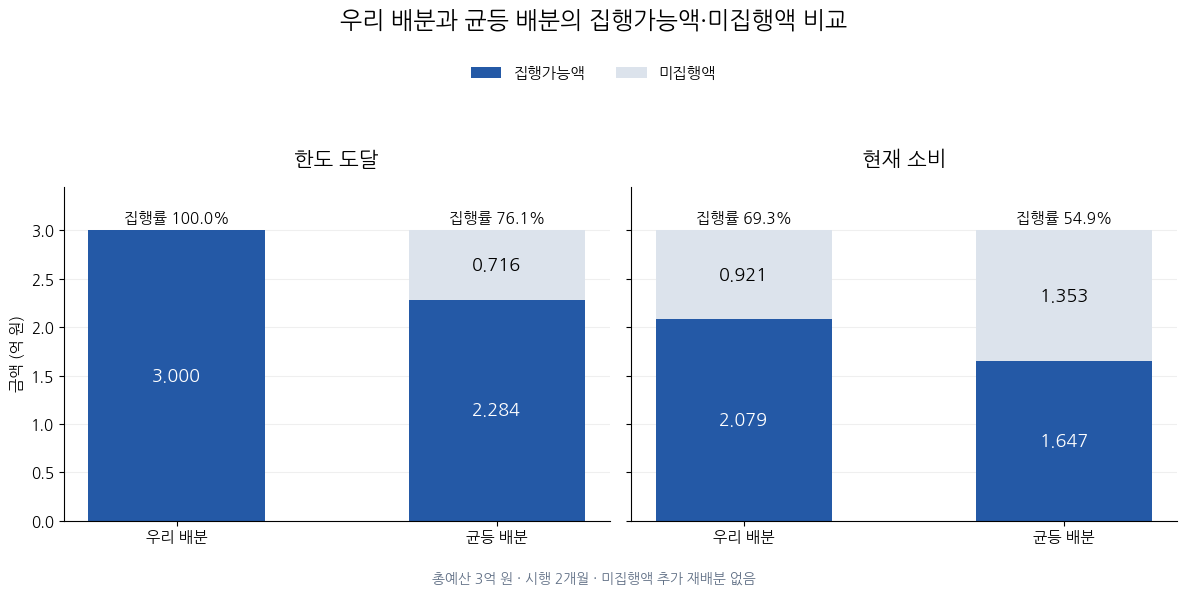

In [ ]:
df = budget_df.copy()

# 집행가정 표기 통일
df["집행가정"] = df["집행가정"].replace({
    "할인한도 도달": "한도 도달",
    "현재 소비 수준": "현재 소비",
})

methods = ["우리 배분", "균등 배분"]
cases = ["한도 도달", "현재 소비"]

assert not df.duplicated(["집행가정", "배분 방식"]).any()

fig, axes = plt.subplots(
    1, 2, figsize=(12, 6), sharey=True
)

for ax, case in zip(axes, cases):
    data = (
        df[df["집행가정"] == case]
        .set_index("배분 방식")
        .loc[methods]
    )

    # 원 → 억 원
    spent = data["집행가능액_원"] / 100_000_000
    unspent = data["미집행액_원"] / 100_000_000

    ax.bar(
        methods, spent,
        width=0.55, color=BLUE,
        label="집행가능액"
    )
    ax.bar(
        methods, unspent,
        bottom=spent,
        width=0.55, color=GRAY,
        label="미집행액"
    )

    for i, (s, u) in enumerate(zip(spent, unspent)):
        # 집행가능액: 파란 막대 내부
        ax.text(
            i, s / 2, f"{s:.3f}",
            ha="center", va="center",
            color="white", fontsize=13, fontweight="bold"
        )

        # 미집행액: 회색 막대 내부
        if u > 0:
            ax.text(
                i, s + u / 2, f"{u:.3f}",
                ha="center", va="center",
                fontsize=13, fontweight="bold"
            )

        # 막대 상단에 집행률 표시
        execution_rate = s / (s + u) * 100
        ax.text(
            i, s + u + 0.08,
            f"집행률 {execution_rate:.1f}%",
            ha="center", fontsize=11
        )

    ax.set_title(case, fontsize=15, fontweight="bold", pad=15)
    ax.set_ylim(0, 3.45)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("금액 (억 원)")

fig.suptitle(
    "우리 배분과 균등 배분의 집행가능액·미집행액 비교",
    fontsize=17, fontweight="bold", y=0.98
)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.91),
    ncol=2, frameon=False
)

fig.text(
    0.5, 0.025,
    "총예산 3억 원 · 시행 2개월 · 균등 배분은 남은 예산을 재배분하지 않음",
    ha="center", fontsize=10, color="#617086"
)

fig.tight_layout(rect=[0, 0.06, 1, 0.84])

fig.savefig(
    "3-4_집행가능액_미집행액_비교.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

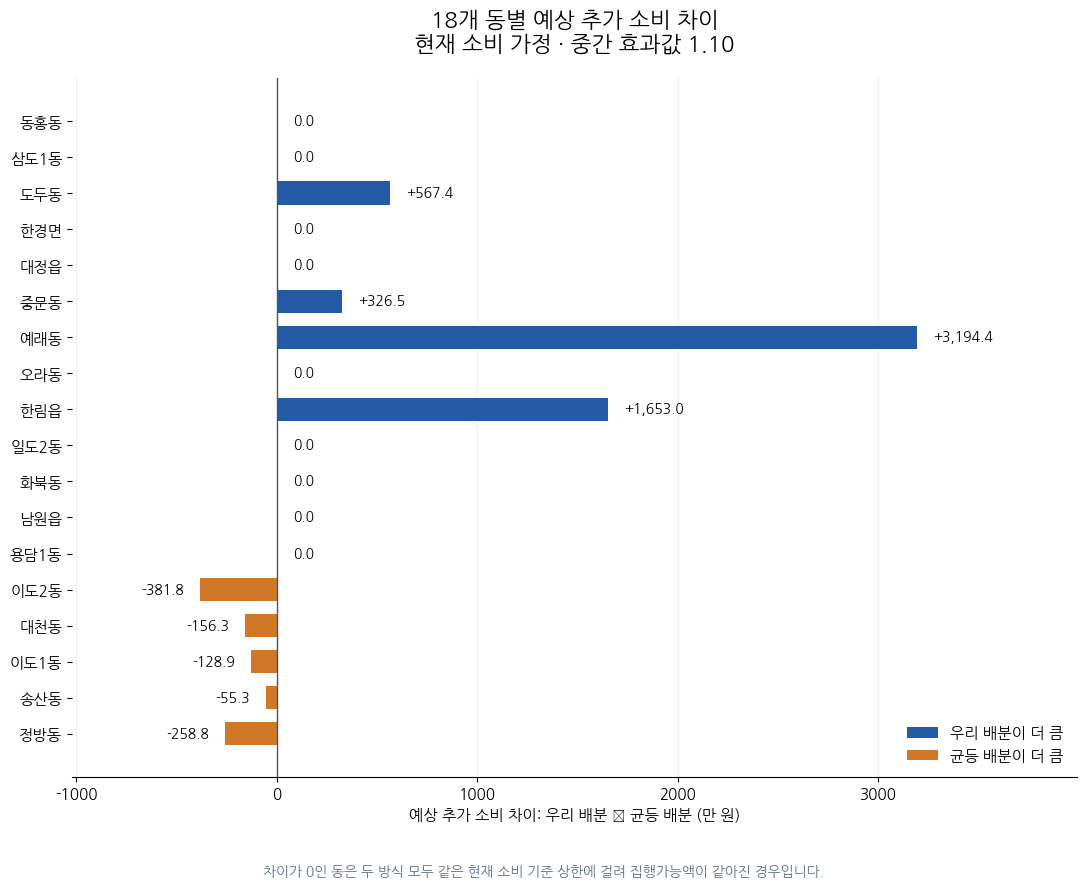

In [ ]:
df = difference_df.copy()

# 합계 행은 지역별 그래프에서 제외
df["행정동"] = df["행정동"].astype(str).str.strip()
df = df[df["행정동"] != "합계"].copy()

assert len(df) == 18, "합계 행을 제외하면 18개 동이어야 합니다."
assert df["행정동"].is_unique, "행정동이 중복되었습니다."

# 중간 효과값(1.10)의 차이 사용: 원 → 만 원
df["차이_만원"] = pd.to_numeric(
    df["중간차이_원"]
) / 10_000

values = df["차이_만원"]
colors = [
    BLUE if value > 0 else ORANGE if value < 0 else GRAY
    for value in values
]

fig, ax = plt.subplots(figsize=(11, 9))

ax.barh(
    df["행정동"], values,
    color=colors, height=0.65
)

# CSV의 지역 순서 유지: 첫 번째 동을 위에 표시
ax.invert_yaxis()
ax.axvline(0, color="#475569", linewidth=1)

# 금액 표시와 여백 설정
scale = max(values.abs().max(), 1)
offset = scale * 0.025

for i, value in enumerate(values):
    if value > 0:
        label, x, align = f"+{value:,.1f}", value + offset, "left"
    elif value < 0:
        label, x, align = f"{value:,.1f}", value - offset, "right"
    else:
        label, x, align = "0.0", offset, "left"

    ax.text(
        x, i, label,
        va="center", ha=align, fontsize=10
    )

ax.set_xlim(
    min(values.min(), 0) - scale * 0.20,
    max(values.max(), 0) + scale * 0.25
)
ax.set_xlabel("예상 추가 소비 차이: 우리 배분 - 균등 배분 (만 원)")
ax.set_title(
    "18개 동별 예상 추가 소비 차이\n"
    "현재 소비 가정 · 중간 효과값 1.10",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)

ax.legend(
    handles=[
        Patch(facecolor=BLUE, label="우리 배분이 더 큼"),
        Patch(facecolor=ORANGE, label="균등 배분이 더 큼"),
    ],
    loc="lower right", frameon=False
)

fig.text(
    0.5, 0.02,
    "차이가 0인 동은 두 방식 모두 같은 현재 소비 기준 상한에 걸려 "
    "집행가능액이 같아진 경우입니다.",
    ha="center", fontsize=10, color="#617086"
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

fig.savefig(
    "3-4_동별_추가소비차이_중간효과.png",
    dpi=300, bbox_inches="tight"
)
plt.show()